# COU 07506 Digital Signal Processing
## Week 2 -Lab 1A: Sampling,Aliasing and Quantization
- **NAME:** ABEDNEGO AGUSTINO KUBOKO
- **REGISTRATION NUMBER:** 240647459881
- **DATE:** 23/11/2026

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

print("All libraries loaded!")

All libraries loaded!


## Pre-lab Questions

### (a) A 7 kHz tone is sampled at 10 kHz. What frequency appears?
- Nyquist frequency = fs/2 = 10/2 = 5 kHz
- 7 kHz is above 5 kHz, so it will alias
- Alias formula: F_alias = |F - k·fs|, choosing k to give the smallest result
- With k = 1: |7 - 10| = 3 kHz

**Answer:** The 7 kHz tone appears as a **3 kHz** tone.

### (b) Δ and SQNR for an 8-bit quantizer with a ±1 V range
- Number of levels = 2^8 = 256
- Δ = 2Xm / 2^B = 2 V / 256 = 0.0078125 V ≈ **7.81 mV**
- SQNR ≈ 6.02B + 1.76 = 6.02(8) + 1.76 = **49.92 dB**

## Task 2.1 — Aliasing of a sinusoid

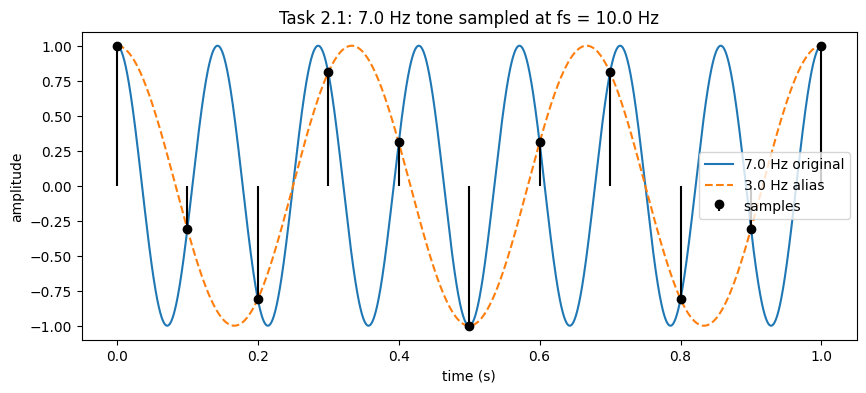

Alias frequency = 3.0 Hz


In [26]:
f0 = 7.0
fs = 10.0

t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs) + 1)
tn = n / fs

f_alias = abs(f0 - fs*round(f0/fs))

plt.figure(figsize=(10, 4))
plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz original")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")
plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ", label="samples")
plt.title(f"Task 2.1: {f0} Hz tone sampled at fs = {fs} Hz")
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.legend()
plt.show()

print("Alias frequency =", f_alias, "Hz")

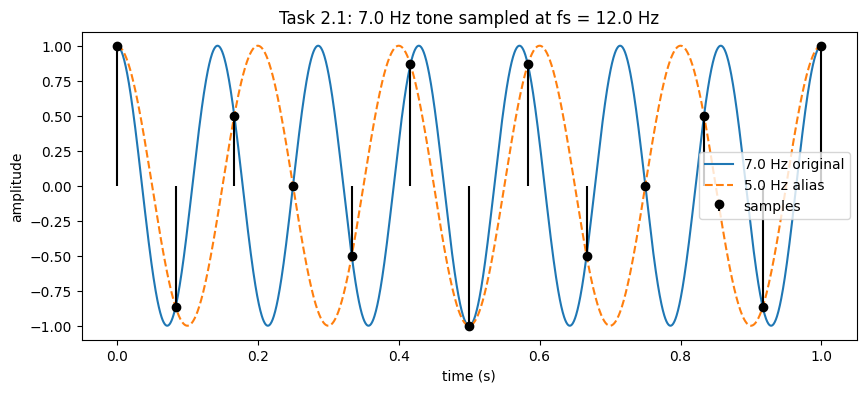

fs = 12.0 Hz -> Nyquist = 6.0 Hz -> alias frequency = 5.0 Hz


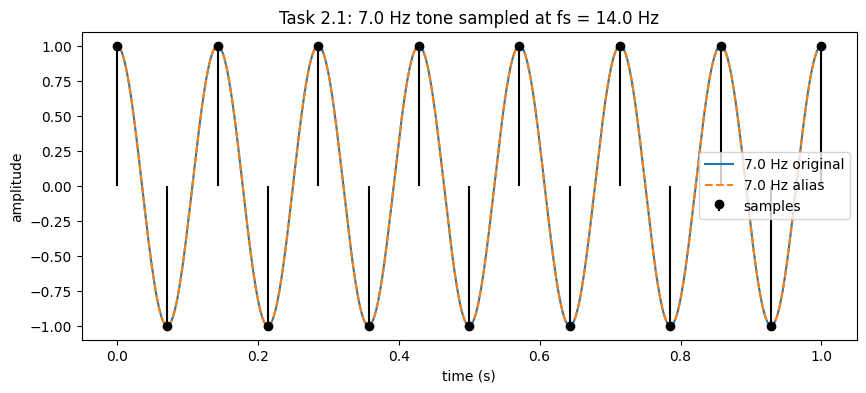

fs = 14.0 Hz -> Nyquist = 7.0 Hz -> alias frequency = 7.0 Hz


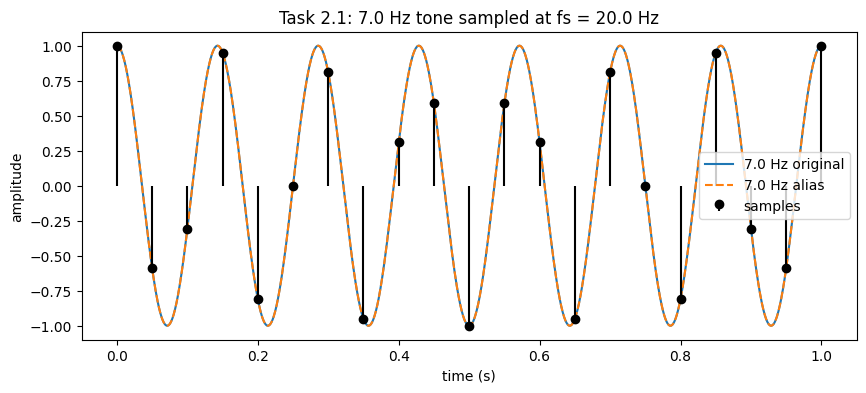

fs = 20.0 Hz -> Nyquist = 10.0 Hz -> alias frequency = 7.0 Hz


In [27]:
f0 = 7.0

for fs in [12.0, 14.0, 20.0]:
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    f_alias = abs(f0 - fs*round(f0/fs))

    plt.figure(figsize=(10, 4))
    plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz original")
    plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")
    plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ", label="samples")
    plt.title(f"Task 2.1: {f0} Hz tone sampled at fs = {fs} Hz")
    plt.xlabel("time (s)")
    plt.ylabel("amplitude")
    plt.legend()
    plt.show()

    print(f"fs = {fs} Hz -> Nyquist = {fs/2} Hz -> alias frequency = {f_alias} Hz")

### Alias table (F = 7 Hz)

| fs (Hz) | Nyquist fs/2 (Hz) | Aliasing? | Hand calculation \|F - k·fs\| | Measured alias (Hz) |
|---|---|---|---|---|
| 10 | 5 | Yes | \|7 - 1×10\| = 3 | 3.0 |
| 12 | 6 | Yes | \|7 - 1×12\| = 5 | 5.0 |
| 14 | 7 | Borderline (F = fs/2) | \|7 - 0×14\| = 7 | 7.0 |
| 20 | 10 | No | \|7 - 0×20\| = 7 | 7.0 |

**Observation:** When fs is less than 2F (14 Hz), the 7 Hz tone appears at a lower, false frequency. When fs is greater than 2F, the tone keeps its true frequency. Thus,the hand calculations agree with the code results.

In [28]:
!ffmpeg -y -i Abed.ogg my_voice.wav

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

## Task 2.2 — Hear aliasing

Sampling rate = 48000 Hz
Duration = 9.05 s


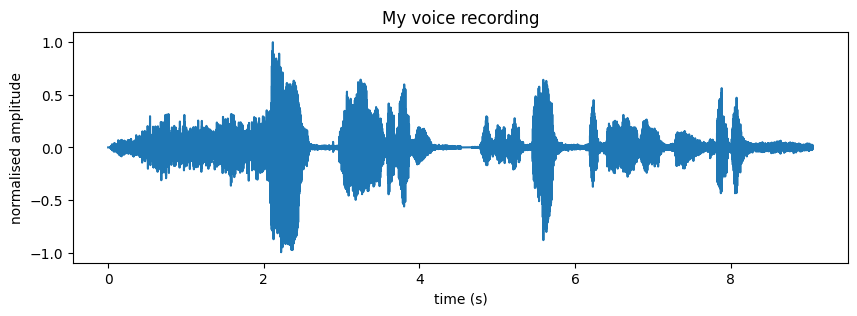

In [29]:
fs_voice, x_voice = wavfile.read("my_voice.wav")
x_voice = x_voice.mean(axis=1) if x_voice.ndim > 1 else x_voice.astype(float)
x_voice = x_voice / np.max(np.abs(x_voice))

print("Sampling rate =", fs_voice, "Hz")
print("Duration =", round(len(x_voice)/fs_voice, 2), "s")

t_voice = np.arange(len(x_voice)) / fs_voice
plt.figure(figsize=(10, 3))
plt.plot(t_voice, x_voice)
plt.title("My voice recording")
plt.xlabel("time (s)")
plt.ylabel("normalised amplitude")
plt.show()

display(Audio(x_voice, rate=fs_voice))

In [30]:
for k in [2, 4, 8]:
    naive = x_voice[::k]
    proper = signal.decimate(x_voice, k, ftype="fir")
    new_fs = fs_voice // k

    print(f"k = {k}: new fs = {new_fs} Hz, Nyquist = {new_fs/2} Hz")
    print("Naive (no filter):")
    display(Audio(naive, rate=new_fs))
    print("Proper (anti-aliasing filter):")
    display(Audio(proper, rate=new_fs))

k = 2: new fs = 24000 Hz, Nyquist = 12000.0 Hz
Naive (no filter):


Proper (anti-aliasing filter):


k = 4: new fs = 12000 Hz, Nyquist = 6000.0 Hz
Naive (no filter):


Proper (anti-aliasing filter):


k = 8: new fs = 6000 Hz, Nyquist = 3000.0 Hz
Naive (no filter):


Proper (anti-aliasing filter):


### Listening observations (Task 2.2)

- **k = 2 (fs = 24 kHz):** little difference from my original voice.
- **k = 4 (fs = 12 kHz):** the naive version has some background noise that was not in my original voice.
- **k = 8 (fs = 6 kHz):** the naive version is harsh and distorted with whistles and aliasing.

## Task 2.3 — A uniform quantizer

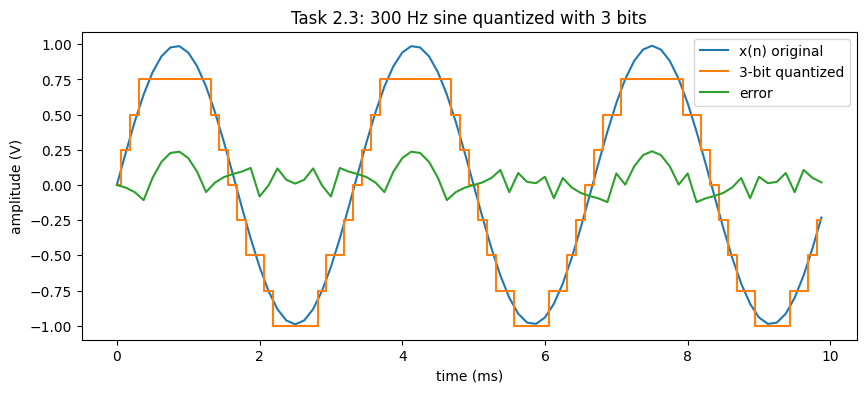

In [31]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)

plt.figure(figsize=(10, 4))
plt.plot(t*1e3, x, label="x(n) original")
plt.step(t*1e3, xq, where="mid", label="3-bit quantized")
plt.plot(t*1e3, x - xq, label="error")
plt.title("Task 2.3: 300 Hz sine quantized with 3 bits")
plt.xlabel("time (ms)")
plt.ylabel("amplitude (V)")
plt.legend()
plt.show()

## Task 2.4 — Verifing the 6 dB-per-bit rule

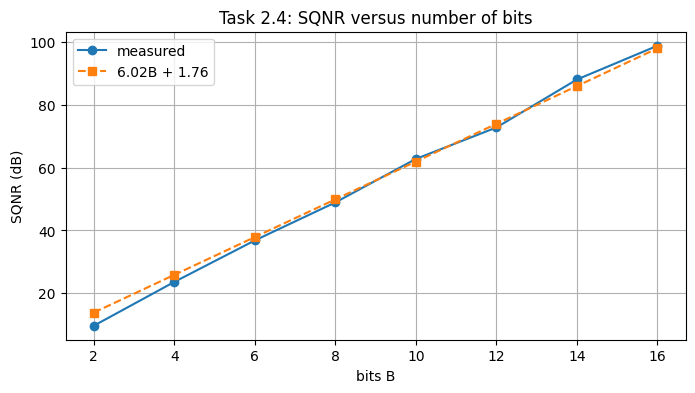

B =  2: measured =   9.60 dB, theory =  13.80 dB
B =  4: measured =  23.58 dB, theory =  25.84 dB
B =  6: measured =  36.81 dB, theory =  37.88 dB
B =  8: measured =  48.93 dB, theory =  49.92 dB
B = 10: measured =  62.81 dB, theory =  61.96 dB
B = 12: measured =  72.84 dB, theory =  74.00 dB
B = 14: measured =  88.13 dB, theory =  86.04 dB
B = 16: measured =  98.91 dB, theory =  98.08 dB


In [32]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]
theory = 6.02*bits + 1.76

plt.figure(figsize=(8, 4))
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, theory, "s--", label="6.02B + 1.76")
plt.title("Task 2.4: SQNR versus number of bits")
plt.xlabel("bits B")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.grid(True)
plt.show()

for B, m, th in zip(bits, meas, theory):
    print(f"B = {B:2d}: measured = {m:6.2f} dB, theory = {th:6.2f} dB")

## Task 2.5 — Quantization of my voice

In [33]:
for B in [4, 8, 12]:
    xq_voice = quantize(x_voice, B)
    sqnr = 10*np.log10(np.sum(x_voice**2) / np.sum((x_voice - xq_voice)**2))
    print(f"{B} bits: measured SQNR = {sqnr:.2f} dB, sine-wave theory = {6.02*B + 1.76:.2f} dB")
    display(Audio(xq_voice, rate=fs_voice))

4 bits: measured SQNR = 12.23 dB, sine-wave theory = 25.84 dB


8 bits: measured SQNR = 34.79 dB, sine-wave theory = 49.92 dB


12 bits: measured SQNR = 58.80 dB, sine-wave theory = 74.00 dB


## Analysis Questions

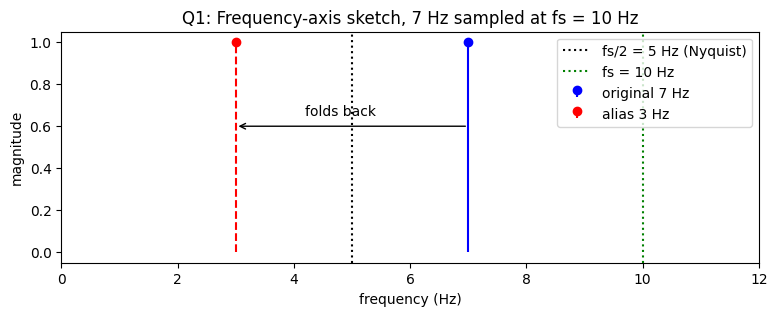

In [34]:
plt.figure(figsize=(9, 3))
plt.stem([7], [1], linefmt="b-", markerfmt="bo", basefmt=" ", label="original 7 Hz")
plt.stem([3], [1], linefmt="r--", markerfmt="ro", basefmt=" ", label="alias 3 Hz")
plt.axvline(5, color="k", linestyle=":", label="fs/2 = 5 Hz (Nyquist)")
plt.axvline(10, color="g", linestyle=":", label="fs = 10 Hz")
plt.annotate("", xy=(3, 0.6), xytext=(7, 0.6), arrowprops=dict(arrowstyle="->"))
plt.text(4.2, 0.65, "folds back")
plt.xlim(0, 12)
plt.title("Q1: Frequency-axis sketch, 7 Hz sampled at fs = 10 Hz")
plt.xlabel("frequency (Hz)")
plt.ylabel("magnitude")
plt.legend(loc="upper right")
plt.show()

**Question 1.** With fs = 10 Hz, only frequencies up to fs/2 = 5 Hz can be represented. The 7 Hz tone is 2 Hz above the Nyquist frequency, so it folds back (mirrors) around 5 Hz to 5 − 2 = 3 Hz. Using the formula, F_alias = |7 − 1×10| = 3 Hz. The samples of the 7 Hz and 3 Hz cosines are identical, as shown in Task 2.1, so after sampling the tone appears at 3 Hz.

**Question 2.** In the naive version, the high parts of my voice (above 3 kHz) folded back and landed on the same frequencies as the real lower parts of my voice. After that, the false sounds and the real sounds are mixed together at the same frequencies, so a filter cannot tell which is which and cannot remove one without the other. That is why the anti-aliasing filter must come before the samples are dropped, as signal.decimate does.

**Question 3.** Theory says each extra bit increases SQNR by about 6.02 dB, because each bit doubles the number of levels and halves Δ, which reduces the noise power by a factor of 4 (10·log₁₀4 ≈ 6 dB). My measurement agrees: from B = 8 (48.93 dB) to B = 16 (98.91 dB), the SQNR rose by 49.98 dB over 8 bits, which is about 6.25 dB per bit. For my voice it rose by about 22–24 dB per 4 bits. The only larger difference was at B = 2.

**Question 4.**
- **Number of bits:** range ÷ resolution = 100 °C ÷ 0.01 °C = 10 000 levels. 2^13 = 8192 is not enough, while 2^14 = 16 384 is enough, so a **14-bit** ADC is needed (which gives a resolution of 100/16384 ≈ 0.006 °C).
- **Sampling rate:** the temperature changes by at most 0.1 °C per second, so a change of one resolution step (0.01 °C) takes at least 0.01/0.1 = 0.1 s. Sampling at **10 Hz** (every 0.1 s) captures every change of 0.01 °C. A temperature signal changes very slowly, so a rate of 10–20 Hz is more than enough and avoids aliasing.

## AI-use statement
I used Claude (Anthropic) to guide me step by step through Lab 1A: explaining the theory, explaining code lines, fixing notebook formatting errors, and helping me phrase my observations and analysis answers. I checked the results against theory: the alias frequencies matched |F − k·fs| calculated by hand, and the measured SQNR values matched 6.02B + 1.76 dB.